<a href="https://colab.research.google.com/github/mafaiziyas/sp500-market-segmentation-fintech-analytics/blob/main/Task_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

folder = "/content/drive/MyDrive/sp500 CW/data_snapshots"

Mounted at /content/drive


In [5]:
#Task 3.2.1

import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

#Adding each share's sector to the cluster labels
inc = pd.read_csv(f"{folder}/inclusion_exclusion_log.csv")
final = pd.read_csv(f"{folder}/cluster_labels_final.csv", index_col="Ticker")
final["sector"] = inc.set_index("YF_Ticker")["GICS Sector"].reindex(final.index)
print("Shares with no sector:", final["sector"].isna().sum())

# Sector mix of each cluster, in % (plus the whole sample for comparison)
all_shares = final["sector"].value_counts(normalize=True) * 100
risk_sector = pd.crosstab(final["ward_risk"], final["sector"], normalize="index") * 100
act_sector = pd.crosstab(final["ward_activity"], final["sector"], normalize="index") * 100
risk_sector.loc["All shares"] = all_shares
act_sector.loc["All shares"] = all_shares
print("Risk/return clusters, sector %"); display(risk_sector.round(0))
print("Trading activity clusters, sector %"); display(act_sector.round(0))

# To see how do the risk clusters and activity clusters overlap?
print(pd.crosstab(final["ward_risk"], final["ward_activity"], rownames=["Risk cluster"], colnames=["Activity cluster"]))
print("ARI:", round(adjusted_rand_score(final["ward_risk"], final["ward_activity"]), 3))

Shares with no sector: 0
Risk/return clusters, sector %


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
ward_risk,,,,,,,,,,,
1,5.0,12.0,0.0,4.0,14.0,2.0,23.0,32.0,3.0,3.0,1.0
2,3.0,12.0,2.0,0.0,16.0,13.0,18.0,22.0,7.0,7.0,1.0
3,5.0,9.0,5.0,16.0,29.0,8.0,11.0,2.0,3.0,3.0,8.0
4,4.0,4.0,21.0,0.0,3.0,21.0,12.0,3.0,5.0,10.0,18.0
All shares,4.0,10.0,7.0,4.0,15.0,12.0,16.0,15.0,5.0,6.0,6.0


Trading activity clusters, sector %


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
ward_activity,,,,,,,,,,,
1,3.0,12.0,5.0,3.0,16.0,7.0,12.0,25.0,9.0,0.0,9.0
2,0.0,10.0,20.0,0.0,10.0,20.0,0.0,10.0,10.0,0.0,20.0
3,6.0,12.0,7.0,7.0,14.0,13.0,16.0,18.0,2.0,3.0,2.0
4,5.0,9.0,6.0,1.0,15.0,17.0,19.0,10.0,3.0,8.0,6.0
5,3.0,6.0,6.0,4.0,17.0,9.0,19.0,9.0,7.0,12.0,9.0
All shares,4.0,10.0,7.0,4.0,15.0,12.0,16.0,15.0,5.0,6.0,6.0


Activity cluster   1  2   3   4   5
Risk cluster                       
1                 19  1  42  19  11
2                 32  1  61  28  62
3                  8  3  42  16  29
4                 17  5  34  23  35
ARI: 0.009


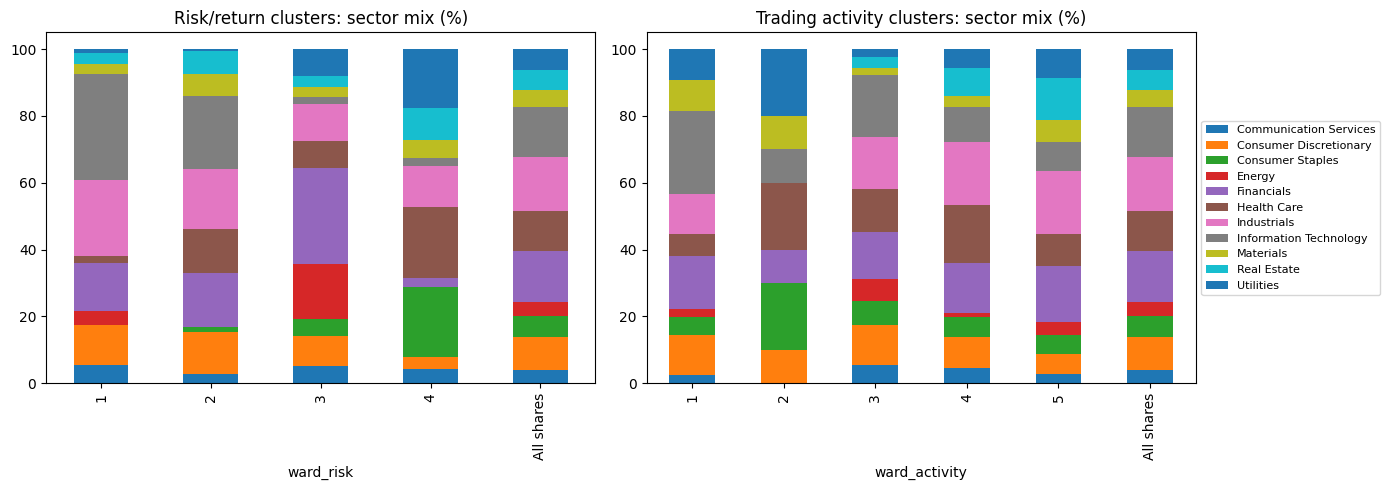

In [6]:

# Chart: stacked bars of sector mix per cluster
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
risk_sector.plot(kind="bar", stacked=True, ax=ax[0], legend=False)
act_sector.plot(kind="bar", stacked=True, ax=ax[1])
ax[0].set_title("Risk/return clusters: sector mix (%)")
ax[1].set_title("Trading activity clusters: sector mix (%)")
ax[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.savefig(f"{folder}/sector_composition.png", dpi=200, bbox_inches="tight")
plt.show()

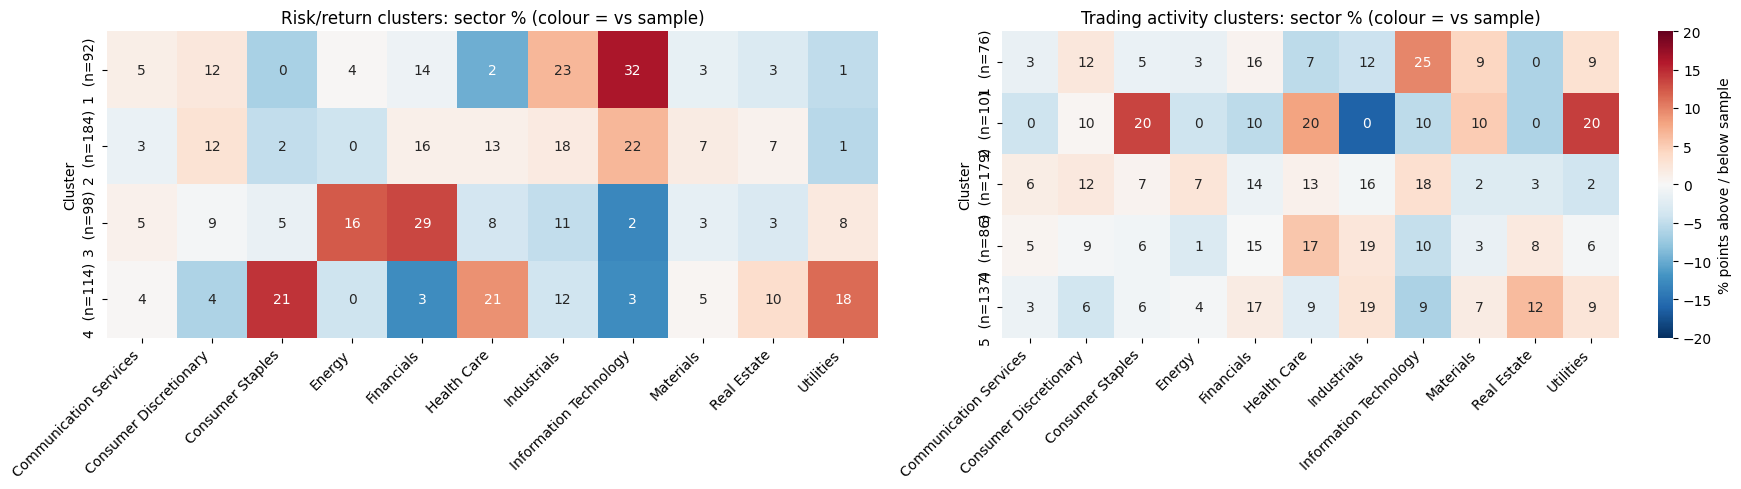

In [7]:
import seaborn as sns

def sector_heatmap(table, cluster_col, ax, title, cbar=False):
    base = all_shares.reindex(table.columns) # sample share per sector
    body = table.drop("All shares")   # one row per cluster
    diff = body - base    # percentage points vs sample
    n = final[cluster_col].value_counts()   # cluster sizes
    body.index = [f"{i}  (n={n[i]})" for i in body.index]
    diff.index = body.index
    sns.heatmap(diff, annot=body.round(0), fmt=".0f", cmap="RdBu_r",
                center=0, vmin=-20, vmax=20, cbar=cbar, ax=ax,
                cbar_kws={"label": "% points above / below sample"})
    ax.set_title(title); ax.set_ylabel("Cluster"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
sector_heatmap(risk_sector, "ward_risk", ax[0], "Risk/return clusters: sector % (colour = vs sample)")
sector_heatmap(act_sector, "ward_activity", ax[1], "Trading activity clusters: sector % (colour = vs sample)", cbar=True)
plt.tight_layout()
plt.savefig(f"{folder}/sector_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()